# Prueba Intertrimestral

**Nombre:** Álvaro  
**Apellidos:** Moraga 

**Tiempo de la prueba:** 2 horas  
**Asignatura:** Desarrollo de Aplicaciones para la Visualización de Datos  
**Fecha:** 19 de octubre de 2027  

## Instrucciones

- Escribe **código limpio y autoexplicativo**.  
- Se pueden utilizar **los materiales de clase**.  
- Se puede utilizar **internet** para búsqueda de dudas y documentación.  
- **No se puede utilizar ningún tipo de LLM** (ChatGPT, Copilot, Gemini, etc.).  
- **No se puede utilizar mensajería instantánea**.  
- Al finalizar, **sube tu notebook a GitHub** y envía el enlace del fichero según las instrucciones del profesor.

**[Subé el enlace aquí](https://forms.cloud.microsoft/e/vSwHis0f1B)**

## Dataset “City Micromobility Hourly”

El fichero `city_micromobility_hourly.csv` contiene **alquileres horarios** de bicicletas y patinetes compartidos en una ciudad (ene 2025 – dic 2026): meteorología, tipo de día, usuarios ocasionales/abonados, duración media, ingresos y una etiqueta de alta demanda.

Hay un `.txt` con la descripción de las variables en la misma carpeta.


## Inicialización de librerías


In [1]:
from datetime import datetime, timedelta, date
from pathlib import Path
import json
import pandas as pd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

# Ejercicio 1 — Programación (2 puntos)

a) (0.6 pts) Crea una función `rental_fee(duration_min, bike_type, is_member)` que calcule la tarifa de un viaje en euros, redondeada a **dos decimales**, con estas reglas:

- Tarifa base: **1.00 €** si `bike_type == "classic"`, **1.50 €** si `bike_type == "electric"`.
- Coste por minuto: **0.05 €/min** (classic) o **0.08 €/min** (electric).
- Si `is_member` es `True`, aplica un **20 % de descuento** sobre el total.
- Si `bike_type` no es `"classic"` ni `"electric"`, lanza `ValueError`.

Ejemplo orientativo: `rental_fee(20, "classic", False)` → `2.00`.


In [40]:
def rental_fee(duration_min, bike_type, is_member):
    if bike_type == "classic":
        base_fee = 1.00
        
        price_per_minute = 0.05

    elif bike_type == "electric":
        base_fee = 1.50

        price_per_minute = 0.08
    else:
        raise ValueError('bike_type debe ser classic o electric') #devuelvo error

    total = base_fee + duration_min * price_per_minute
    if is_member:
        total *= 0.80

    return round(total, 2) 
    
#Pongo dos ejemplos de prueba

print(rental_fee(20, "classic", False))  # 2.0
print(rental_fee(20, "electric", True))  # 2.48

2.0
2.48


b) (0.6 pts) Crea una función `demand_label(total_rentals, threshold)` que devuelva `"Alta"` si `total_rentals >= threshold`, `"Media"` si está entre `threshold/2` (incluido) y `threshold` (excluido), y `"Baja"` en caso contrario.


In [39]:
def demand_label(total_rentals, threshold):
    if total_rentals >= threshold:

        return "Alta"
    elif total_rentals >= threshold/ 2:
        return "Media"
    else:
        return"Baja"

    demanda_label()

#prueba que realizado para los tres casos
print(demand_label(50, 40))  #Alta
print(demand_label(20, 40))  #Media
print(demand_label(10, 40))  #Baja

Alta
Media
Baja


c) (0.6 pts) Genera un DataFrame llamado `tripsDemo` con **al menos 10 filas** y columnas:

- `duration_min` (float)
- `bike_type` (`"classic"` o `"electric"`)
- `is_member` (bool)
- `fee` (calculada con `rental_fee`)
- `total_rentals` (int, inventado)
- `demand` (calculada con `demand_label`, usando por ejemplo `threshold=40`)

Muestra el DataFrame completo.


In [ ]:
tripsDemo = pd.DataFrame({
    "duration_min": [5.0, 10.5, 15.0, 20.0, 25.5, 30.0, 12.0, 8.5, 45.0, 60.0],
    "bike_type": ["classic", "electric", "classic", "electric", "classic","electric", "classic", "electric", "classic", "electric"],
    "is_member": [False, True, True, False, False, True, False, True, True, False],
    "total_rentals": [5, 15, 19, 20, 25, 39, 40, 45, 60, 80]
}) #lo he hardocedado, lo veo mas facil, pero pordría haberlo hecho con numpy random, etc.

tripsDemo["fee"]=tripsDemo.apply(

    lambda trip: rental_fee(trip["duration_min"], trip["bike_type"], trip["is_member"]),
    axis=1
)
tripsDemo["demand"] = tripsDemo["total_rentals"].apply(
    lambda total:demand_label(total, threshold=40)
)
tripsDemo = tripsDemo[["duration_min","bike_type","is_member","fee","total_rentals","demand"]]

print(tripsDemo.to_string(index=False))

 duration_min bike_type  is_member  fee  total_rentals demand
          5.0   classic      False 1.25              5   Baja
         10.5  electric       True 1.87             15   Baja
         15.0   classic       True 1.40             19   Baja
         20.0  electric      False 3.10             20  Media
         25.5   classic      False 2.28             25  Media
         30.0  electric       True 3.12             39  Media
         12.0   classic      False 1.60             40   Alta
          8.5  electric       True 1.74             45   Alta
         45.0   classic       True 2.60             60   Alta
         60.0  electric      False 6.30             80   Alta


d) (0.2 pts) Integra ambas funciones en una clase `MicromobilityTools` que, a partir de listas/arrays de `duration_min`, `bike_type` e `is_member`, calcule las tarifas y (opcionalmente) etiquete demanda a partir de una lista de `total_rentals` y un `threshold`.


In [51]:
class MicromobilityTools:
    rental_fee = staticmethod(rental_fee)
    demand_label = staticmethod(demand_label)

    def calculate(self, duration_min, bike_type, is_member, total_rentals=None, threshold=40):
        if not (len(duration_min) == len(bike_type) == len(is_member)):
            raise ValueError("Las listas de viajes deben tener la misma longitud")
        if total_rentals is not None and len(total_rentals) != len(duration_min):
            raise ValueError("total_rentals debe tener la misma longitud que los viajes")

        result = pd.DataFrame({
            "duration_min": list(duration_min),
            "bike_type": list(bike_type),
            "is_member": list(is_member)
        })

        result["fee"] = [
            self.rental_fee(duration, bike, member)
            for duration,bike,member in zip(duration_min,bike_type, is_member)
        ]
        if total_rentals is not None:
            result["total_rentals"]= list(total_rentals)
            result["demand"]= [
                self.demand_label(total, threshold) for total in total_rentals
            ]
        return result


tools = MicromobilityTools()
tripsWithTools = tools.calculate(

    tripsDemo["duration_min"].tolist(),
    tripsDemo["bike_type"].tolist(),

    tripsDemo["is_member"].tolist(),
    total_rentals=tripsDemo["total_rentals"].tolist(),
    threshold=40
)
print(tripsWithTools.to_string(index=False))

 duration_min bike_type  is_member  fee  total_rentals demand
          5.0   classic      False 1.25              5   Baja
         10.5  electric       True 1.87             15   Baja
         15.0   classic       True 1.40             19   Baja
         20.0  electric      False 3.10             20  Media
         25.5   classic      False 2.28             25  Media
         30.0  electric       True 3.12             39  Media
         12.0   classic      False 1.60             40   Alta
          8.5  electric       True 1.74             45   Alta
         45.0   classic       True 2.60             60   Alta
         60.0  electric      False 6.30             80   Alta


## Ejercicio 2 — Exploración y visualización (3 puntos)

a) (0.75 pts) Carga `city_micromobility_hourly.csv` en un DataFrame `mobilityData`. Muestra las 5 primeras filas y el número de filas y columnas.


In [52]:
mobilityData = pd.read_csv("city_micromobility_hourly.csv")
display(mobilityData.head())
print(f"Numero de filas: {mobilityData.shape[0]}")
print(f"Numero de columnas: {mobilityData.shape[1]}")

,datetime,year,month,day,hour,weekday,season,is_holiday,is_weekend,is_workingday,...,wind_kmh,precip_mm,casual_users,member_users,total_rentals,avg_trip_min,avg_distance_km,electric_share,revenue_eur,high_demand
0,2025-01-01 00:00:00,2025,1,1,0,2,Winter,1,0,0,...,9.7,0.0,2,8,10,23.3,4.94,0.391,10.83,0
1,2025-01-01 01:00:00,2025,1,1,1,2,Winter,1,0,0,...,2.8,0.0,1,5,6,17.3,3.92,0.327,5.35,0
2,2025-01-01 02:00:00,2025,1,1,2,2,Winter,1,0,0,...,9.0,0.0,1,4,5,17.3,4.24,0.405,4.77,0
3,2025-01-01 03:00:00,2025,1,1,3,2,Winter,1,0,0,...,5.4,0.0,2,10,12,17.3,3.98,0.408,10.88,0
4,2025-01-01 04:00:00,2025,1,1,4,2,Winter,1,0,0,...,2.4,0.0,1,4,5,21.6,5.90,0.336,5.16,0


Numero de filas: 17520
Numero de columnas: 23


b) (0.75 pts) Crea una función `describeData(dataFrame)` que, para cada columna, devuelva: tipo de dato, número de nulos y porcentaje de nulos.


In [53]:
def describeData(dataFrame):
    return pd.DataFrame({
        "tipo_dato": dataFrame.dtypes,
        "numero_nulos": dataFrame.isna().sum(),
        "porcentaje_nulos": dataFrame.isna().mean() * 100
    })

c) (0.75 pts) Usa `describeData(mobilityData)` y comenta brevemente (2–3 líneas) qué variables tienen más valores faltantes y qué harías con ellas antes de modelar.


In [ ]:
nullSummary = describeData(mobilityData)
display(nullSummary.sort_values("numero_nulos", ascending=False))

# Las variables con mas nulos son avg_trip_min (255; 1.46 %),humidity (224; 1.28 %), por otro lado, 
# electric_share (182; 1.04 %) y wind_kmh (142; 0.81 %); el resto no tiene nulos. Aunque
# Antes de modelar, eliminaría los nulos porque a pesar de que son muchos, el porcentaje es pequeño, y es más sencillo que imputar la mediana (por ejemplo).
#Sin embargo, como es temporal, puede que estemos perdiendo outliers o datos que expliquen diefrentes cosas. (seguimos mas abajo)

,tipo_dato,numero_nulos,porcentaje_nulos
avg_trip_min,float64,255,1.455479
humidity,float64,224,1.278539
electric_share,float64,182,1.038813
wind_kmh,float64,142,0.810502
datetime,str,0,0.000000
year,int64,0,0.000000
month,int64,0,0.000000
season,str,0,0.000000
weekday,int64,0,0.000000
hour,int64,0,0.000000


d) (0.75 pts) Elabora **dos** visualizaciones:

1. Un gráfico de correlación entre variables numéricas relevantes (por ejemplo `temp_c`, `humidity`, `wind_kmh`, `precip_mm`, `casual_users`, `member_users`, `total_rentals`, `revenue_eur`).
2. Un gráfico que muestre la demanda media (`total_rentals`) por `hour` (y, si quieres, separando fin de semana / laborable).

Comenta 2–3 hallazgos (correlaciones, horas punta, efecto del clima, etc.).


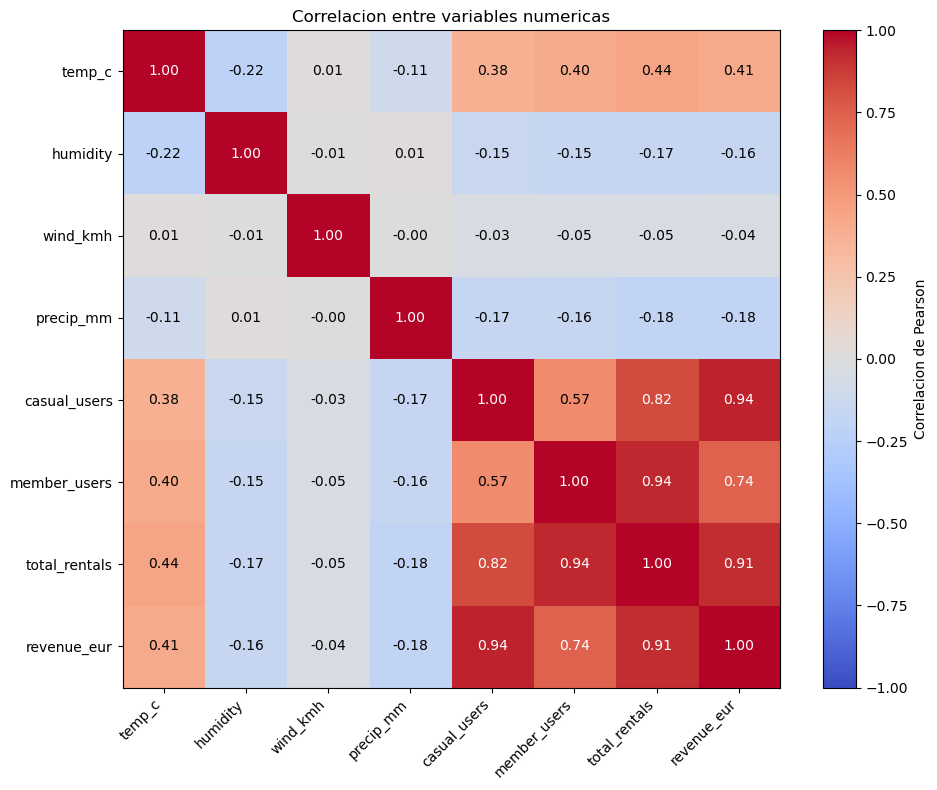

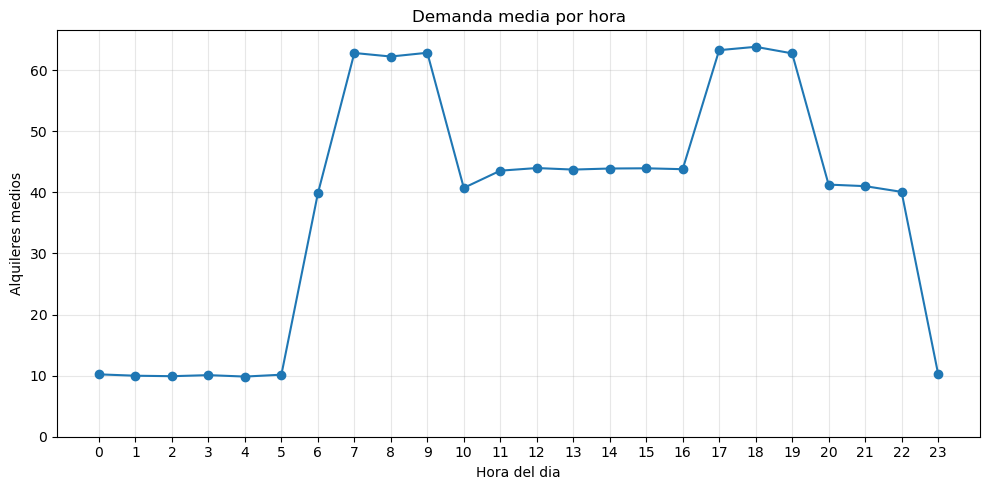

In [ ]:
correlationColumns = [
    "temp_c","humidity","wind_kmh","precip_mm",
    "casual_users","member_users","total_rentals","revenue_eur"
]
correlations = mobilityData[correlationColumns].corr()

#Tengo que recordar poner nombres a los ejess
#Dejar para luego, lo tengo en la plantilla 2 
fig, ax = plt.subplots(figsize=(10, 8))
heatmap = ax.imshow(correlations, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlationColumns)), labels=correlationColumns, rotation=45, ha="right")
ax.set_yticks(range(len(correlationColumns)), labels=correlationColumns)
for row in range(len(correlationColumns)):
    for col in range(len(correlationColumns)):
        value = correlations.iloc[row, col]
        ax.text(col, row, f"{value:.2f}", ha="center", va="center",
                color="white" if abs(value) > 0.6 else "black")
fig.colorbar(heatmap, ax=ax, label="Correlacion de Pearson")
ax.set_title("Correlacion entre variables numericas")
plt.tight_layout()
plt.show()

hourlyDemand = mobilityData.groupby("hour")["total_rentals"].mean()
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(hourlyDemand.index, hourlyDemand.values, marker="o")
ax.set(title="Demanda media por hora", xlabel="Hora del dia", ylabel="Alquileres medios")
ax.set_xticks(range(24))
ax.set_ylim(bottom=0)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# La demanda presenta picos entre las 7-9 h y las 17-19 h; el maximo es a las 18 h (63.82 alquileres medios)
#  La temperatura se asocia positivamente con la demanda (r=0.44); lluvia y humedad, negativamente (r=-0.18 y -0.17)
# Abonados e ingresos tienen correlaciones altas con total_rentals (0.94 y 0.91)y los abonados forman parte del total y los ingresos dependen de los
#  viajes.No implica causalidad

## Ejercicio 3 — Regresión (2 puntos)

Queremos predecir `total_rentals`.

a) (0.25 pts) Define `targetVar = "total_rentals"` y selecciona **3–5** variables predictoras numéricas razonables (p. ej. `hour`, `temp_c`, `humidity`, `wind_kmh`, `precip_mm`, `is_workingday`, `is_weekend`). Construye `X` e `y`, tratando nulos de forma simple (p. ej. eliminar filas o imputar la mediana).


In [57]:
targetVar= "total_rentals"
predictorVars=["hour", "temp_c", "humidity", "precip_mm", "is_workingday"]


regressionData = mobilityData[predictorVars + [targetVar]].dropna() # Seleccionamos variables de contexto y eliminamos las filas con nulos.
X = regressionData[predictorVars]
y = regressionData[targetVar]

print(f"Dimensiones de X: {X.shape}")
print(f"Dimensiones de y: {y.shape}")

Dimensiones de X: (17296, 5)
Dimensiones de y: (17296,)


b) (0.25 pts) Divide en entrenamiento (70 %) y prueba (30 %) con `random_state=42`.


In [58]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42
)

print(f"Filas de entrenamiento: {len(X_train)}")
print(f"Filas de prueba: {len(X_test)}")

Filas de entrenamiento: 12107
Filas de prueba: 5189


c) (0.75 pts) Entrena un `LinearRegression`, calcula **R²** y **MSE** en el conjunto de prueba y comenta el resultado en 1–2 líneas.


In [59]:
linearModel = LinearRegression()
linearModel.fit(X_train, y_train)
y_pred_linear = linearModel.predict(X_test)

r2_linear = r2_score(y_test, y_pred_linear)
mse_linear = mean_squared_error(y_test, y_pred_linear)
print(f"R2 en prueba: {r2_linear:.4f}")
print(f"MSE en prueba: {mse_linear:.2f}")

# El modelo explica aproximadamente el 32 % de la variabilidad en prueba (R2 = 0.3196), con MSE = 403.66. pero es muy abajo, supongo que habra relaciones
#no lineales. Su capacidad predictiva es limitada. 

# Un MSE  muy alto indica que existe una gran diferencia entre los valores  que predice el modelo y los valores reales observados en los datos

R2 en prueba: 0.3196
MSE en prueba: 403.66


d) (0.75 pts) Entrena un `RandomForestRegressor` (mismo split) y compara R² y MSE con la regresión lineal. ¿Cuál funciona mejor y por qué crees que es así?


In [61]:
forestModel = RandomForestRegressor(n_estimators=100, random_state=42)
forestModel.fit(X_train, y_train)
y_pred_forest = forestModel.predict(X_test)

r2_forest = r2_score(y_test, y_pred_forest)
mse_forest = mean_squared_error(y_test, y_pred_forest)
modelComparison = pd.DataFrame({
    "Modelo":["Regresion lineal", "Random Forest"],
    "R2":[r2_linear, r2_forest],
    "MSE":[mse_linear, mse_forest]
})
display(modelComparison)

# Random Forest funciona mejor en prueba: obtiene mayor R2 y menor MSE.

# el random Forest, Puede representar los picos horarios y relaciones no lineales e interacciones entre hora, clima y tipo de dia.

,Modelo,R2,MSE
0,Regresion lineal,0.319621,403.657975
1,Random Forest,0.882448,69.741652


## Ejercicio 4 — Clasificación (2 puntos)

Usa la columna `high_demand` (1 = demanda alta, 0 = no).

a) (0.25 pts) Comprueba el balance de clases (`value_counts` o proporción) de `high_demand`.


In [62]:
classBalance = pd.DataFrame({
    "numero_casos": mobilityData["high_demand"].value_counts(), #Contamos valores
    "porcentaje": mobilityData["high_demand"].value_counts(normalize=True) * 100 #lo pongo así para ponerlo en porcentaje
}).sort_index()
classBalance.index.name = "high_demand"
display(classBalance)

,numero_casos,porcentaje
high_demand,,
0,12071,68.898402
1,5449,31.101598


b) (0.75 pts) Entrena un `LogisticRegression` para predecir `high_demand` usando variables de contexto (hora, clima, tipo de día, etc.). Recuerda preparar `X`/`y` y el split train/test.


In [63]:
classificationPredictors = [
    "hour","temp_c", "humidity", "wind_kmh",
    "precip_mm","is_workingday","is_weekend","is_holiday"
]
classificationData = mobilityData[classificationPredictors + ["high_demand"]].dropna() #eliminamos los nulos
X_class = classificationData[classificationPredictors]
y_class = classificationData["high_demand"]

X_train_class, X_test_class, y_train_class, y_test_class = train_test_split(
    X_class, y_class, test_size=0.30, random_state=42, stratify=y_class
)

logisticModel = LogisticRegression(max_iter=2000, random_state=42)

logisticModel.fit(X_train_class, y_train_class)
y_pred_class = logisticModel.predict(X_test_class)

print(f"Filas de entrenamiento: {len(X_train_class)}")
print(f"Filas de prueba: {len(X_test_class)}")

Filas de entrenamiento: 12011
Filas de prueba: 5148


c) (0.25 pts) Calcula la **accuracy** y muestra la **matriz de confusión**.


Accuracy en prueba: 0.7549 (75.49%)


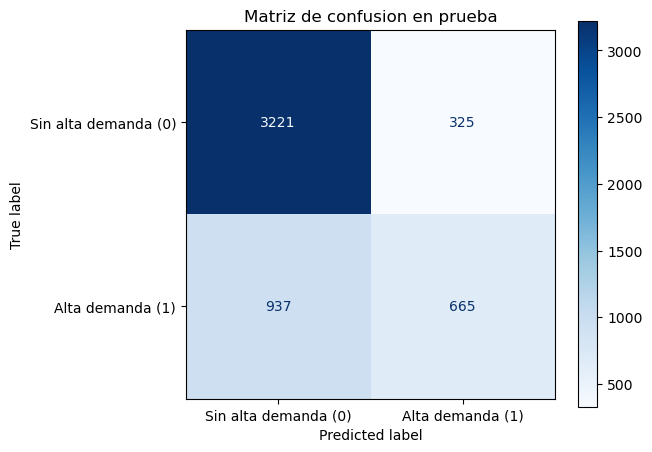

In [64]:
accuracy_class = accuracy_score(y_test_class, y_pred_class)
print(f"Accuracy en prueba: {accuracy_class:.4f} ({accuracy_class:.2%})")

confusionMatrix = confusion_matrix(y_test_class, y_pred_class, labels=[0, 1])
ConfusionMatrixDisplay(
    confusion_matrix=confusionMatrix,
    display_labels=["Sin alta demanda (0)", "Alta demanda (1)"]
).plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusion en prueba")
plt.tight_layout()
plt.show()

d) (0.75 pts) Interpreta qué factores parecen asociarse más a la alta demanda (coeficientes del modelo logístico y/o importancia si usas un árbol; o argumentación basada en tus gráficos del ejercicio 2).


In [ ]:
logisticCoefficients = pd.DataFrame({
    "variable": X_train_class.columns,
    "coeficiente": logisticModel.coef_[0]
})
display(logisticCoefficients.sort_values("coeficiente", ascending=False))

#La temperatura tiene una asociacion positiva con la alta demanda (coeficiente de 0.092 por grado).
#La precipitacion (-2.124 por mm), el viento (-0.034 por km/h) y la humedad (-0.016) se asocian negativamente.

#No se pueden comparar directamente las magnitudes de los coeficientes: las variables tienen unidades diferentes.
#Los gr´sficos del ejercicio 2 muestran picos de demanda entre las 7-9 h y las 17-19 h y el coeficiente positivo de hour resume una tendencia lineal
#  y no representa estos dos picos.

# Los indicadores de tipo de dia estan relacionados entre si, por lo que sus coeficientes individuales deben interpretarse con cuidado 
# ya que estas asociaciones no demuestran causalidad.

,variable,coeficiente
6,is_weekend,1.341090
5,is_workingday,0.808890
7,is_holiday,0.731539
1,temp_c,0.092460
0,hour,0.054395
2,humidity,-0.016294
3,wind_kmh,-0.033569
4,precip_mm,-2.132845


## Ejercicio 5 — Conclusión (1 punto)

En un máximo de **300 palabras**, resume:

* Qué factores (hora, clima, tipo de día, etc.) parecen mover más la demanda de micromovilidad.  
* Qué modelo predictivo te ha funcionado mejor y por qué.  
* Qué mejorarías con más tiempo o datos (más ciudades, eventos, precio dinámico, etc.).


Al finalizar:

**[Subé el enlace aquí](https://forms.cloud.microsoft/e/vSwHis0f1B)**



In [ ]:
#La demanda de micromovilidad presenta picos entre las 7–9 h y las 17–19 h, esto puede ser debido a desplazamientos habituales al trabajo o a los colegios. 
# También, la temperatura se asocia positivamente con los alquileres, mientras que la precipitación, la humedad y el viento muestran relaciones negativas.
#  Estos resultados describen relaciones, pero no demuestran causalidad, por eso necesitamos a humanos que lo analicen y no solo a la IA.

#El modelo que mejor ha predicho el número de alquileres ha sido Random Forest, ya que ha sido el que ha tenido mejor R2 de 0,8824 y un MSE de 69,74,
# frente al R2 de 0,3196 y el MSE de 403,66 de la regresión lineal. Esto es debido a  su capacidad para representar relaciones no lineales
# (como los picos horarios, e interacciones entre variables). Por último, enn clasificación, la regresión logística ha alcanzado una accuracy del 75,47%,
#  aunque ha detectado bastantes casos de alta demanda.

#Si tuviesemos mas tiempo, se podría probar una división temporal de entrenamiento y prueba para evaluar la predicción de periodos futuros,
# ajustaría los hiperparámetros de Random Forest y analizaría precision, recall y F1 en clasificación.
# También incorporaría datos de otras ciudades, eventos, disponibilidad de vehículos y precios para estudiar si mejoran las predicciones y su capacidad
#  de generalización. O incluso podríasmos probar distintos modelos o tecnicas que hemos visto en otras asignaturas, como redes neuronales, series temporales, etc.



